# NumPy et Pandas : des observations aux graphiques

**Objectifs.** Lire les dimensions d’un tableau, appliquer le broadcasting, résumer un DataFrame et tracer une relation avec des unités. Durée : 60–90 min.

Nous suivons ici des mesures de plantes entièrement inventées pour l’exercice. Chaque ligne représente une plante, chaque colonne une variable mesurée.

## 1. Une table devient un tableau numérique

Pour `X.shape == (n, p)`, `n` est le nombre d’observations et `p` le nombre de variables. Une ligne contient les caractéristiques d’une plante.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(12)
heights_cm = rng.normal(45, 8, size=80).clip(20, 75)
widths_cm = 0.42 * heights_cm + rng.normal(0, 3, size=80)
X = np.column_stack([heights_cm, widths_cm])
X.shape, X[:3]

### Exemple numérique : chaque colonne a son rôle

Prenons trois observations et deux variables, `toy = [[2,10], [4,14], [6,18]]`. La moyenne par colonne vaut `[4,14]` : la soustraction par *broadcasting* répète ce vecteur sur les trois lignes. La moyenne selon `axis=1` répond à une autre question et mélange ici des unités potentiellement différentes. Le graphique ci-dessous montre chaque cellule avant et après centrage.

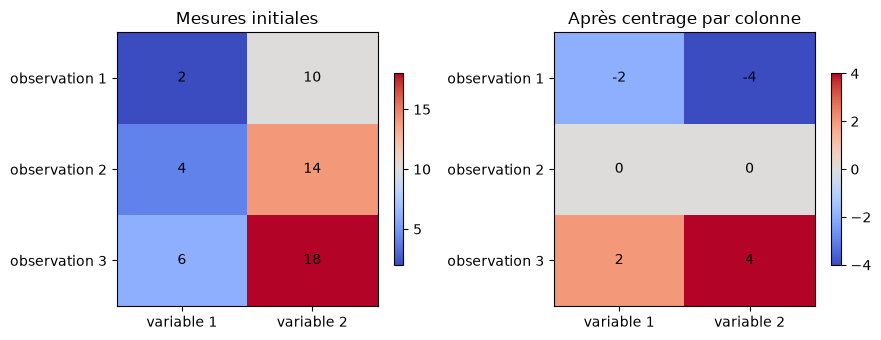

In [ ]:
toy = np.array([[2., 10.], [4., 14.], [6., 18.]])
column_means = toy.mean(axis=0)
toy_centered = toy - column_means
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, values, title in zip(axes, [toy, toy_centered], ['Mesures initiales', 'Après centrage par colonne']):
    image = ax.imshow(values, cmap='coolwarm', aspect='auto')
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            ax.text(column, row, f'{values[row, column]:.0f}', ha='center', va='center')
    ax.set(xticks=[0, 1], xticklabels=['variable 1', 'variable 2'], yticks=range(3), yticklabels=['observation 1', 'observation 2', 'observation 3'], title=title)
    fig.colorbar(image, ax=ax, shrink=0.7)
plt.tight_layout(); plt.show()
print('forme :', toy.shape, '| moyennes colonnes :', column_means, '| moyennes après centrage :', toy_centered.mean(axis=0))

## 2. Broadcasting et produit matriciel

Le broadcasting applique une opération élément par élément lorsque les dimensions sont compatibles. Le produit scalaire additionne les produits coordonnée par coordonnée. Ici, un modèle linéaire calcule une prédiction par ligne : `(n, 2) @ (2,) -> (n,)`.

In [ ]:
center = X.mean(axis=0)
scale = X.std(axis=0)
X_scaled = (X - center) / scale
weights = np.array([0.7, 0.3])
scores = X_scaled @ weights
print('shape de X :', X.shape)
print('moyennes après centrage :', X_scaled.mean(axis=0).round(10))
print('shape des scores :', scores.shape)

## 3. Passer au DataFrame

Pandas donne des noms aux variables et des opérations pratiques pour les inspecter. L’inspection ne remplace pas une décision sur la qualité des mesures.

In [ ]:
plants = pd.DataFrame({'height_cm': heights_cm, 'width_cm': widths_cm})
plants['shape_ratio'] = plants['width_cm'] / plants['height_cm']
print(plants.head())
print('Dimensions :', plants.shape)
print('Valeurs manquantes :\n', plants.isna().sum())
print('Résumé :\n', plants.describe().round(2))

## 4. Lire un fichier sans dépendance externe

En production, le chemin et l’encodage doivent être documentés. Une cellule `StringIO` montre ici l’interface de lecture CSV sans créer de fichier temporaire.

In [ ]:
from io import StringIO

sample_csv = 'species,height_cm\nA,41.2\nB,53.8\nA,48.1\n'
small_table = pd.read_csv(StringIO(sample_csv))
small_table, small_table.groupby('species')['height_cm'].mean()

### JSON et Parquet

Un tableau JSON peut se lire avec `read_json`. Parquet conserve schéma et types, et convient aux tables larges ou partitionnées. Pour lire/écrire Parquet, installer le moteur optionnel `python -m pip install -e ".[parquet]"`. Exemple à exécuter après cette installation :

```python
small_table.to_parquet('sample.parquet', index=False)
restored = pd.read_parquet('sample.parquet')
```

In [ ]:
json_text = '[{"species": "A", "height_cm": 41.2}, {"species": "B", "height_cm": 53.8}]'
json_table = pd.read_json(StringIO(json_text))
json_table

## 5. Visualiser et interpréter

Les axes, unités et titre rendent le graphique lisible hors du notebook. Une association visible ne prouve ni causalité ni utilité prédictive.

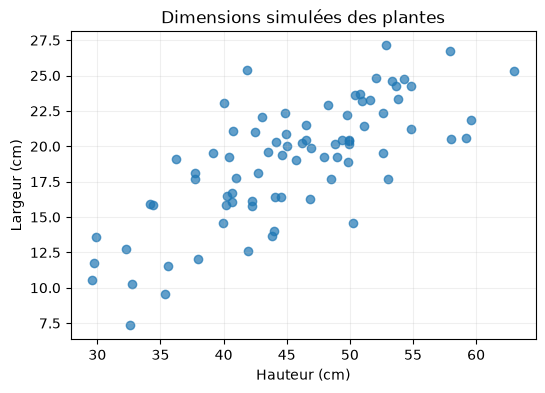

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(plants['height_cm'], plants['width_cm'], alpha=0.7)
ax.set(title='Dimensions simulées des plantes', xlabel='Hauteur (cm)', ylabel='Largeur (cm)')
ax.grid(alpha=0.2)
plt.show()

## 6. Expérience et limites

Le ratio `width/height` permet une comparaison relative, mais il peut devenir instable si le dénominateur est nul ou très petit. Ici les hauteurs sont strictement positives. Modifiez la dispersion du bruit ci-dessous et comparez la corrélation ; le résultat dépend de la graine.

In [ ]:
for noise_level in [1, 5, 12]:
    simulated_width = 0.42 * heights_cm + rng.normal(0, noise_level, size=len(heights_cm))
    print(noise_level, round(float(np.corrcoef(heights_cm, simulated_width)[0, 1]), 3))

### Une expérience a une variabilité

Une seule graine fournit un résultat reproductible, mais ne mesure pas la stabilité d'une conclusion. En répétant la génération 40 fois par niveau de bruit, on distingue la tendance moyenne de la variabilité entre échantillons. Les barres indiquent un écart-type entre répétitions, pas une incertitude causale sur des plantes réelles.

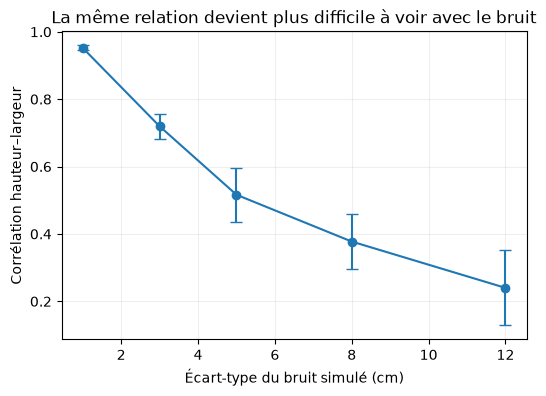

In [ ]:
noise_levels = np.array([1, 3, 5, 8, 12])
repeated_rng = np.random.default_rng(120)
correlations = np.array([[np.corrcoef(heights_cm, 0.42 * heights_cm + repeated_rng.normal(0, level, len(heights_cm)))[0, 1] for _ in range(40)] for level in noise_levels])
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(noise_levels, correlations.mean(axis=1), yerr=correlations.std(axis=1), marker='o', capsize=4)
ax.set(xlabel='Écart-type du bruit simulé (cm)', ylabel='Corrélation hauteur–largeur', title='La même relation devient plus difficile à voir avec le bruit')
ax.grid(alpha=0.2); plt.show()

**Lecture du graphique :** quand la part aléatoire de la largeur augmente, la corrélation observée tend à baisser et varie davantage. Le code n'a pas changé la relation déterministe `0.42 * height` ; il a changé la qualité du signal. Une corrélation ne révèle pas à elle seule la relation causale. **À essayer :** doubler le nombre de plantes et comparer les barres d'erreur.

## À retenir et exercices

- Vérifier `shape`, types et unités avant de calculer.
- `axis=0` résume chaque colonne ; `axis=1` chaque observation.
- Le broadcasting ne remplace pas un produit matriciel.
- Les données simulées valident le code, pas une conclusion sur des plantes réelles.

Exercices séparés : [`01_python.ipynb`](../../exercises/beginner/01_python.ipynb).